# Loan Portfolio & Customer Behaviour Analysis

**Objective:** Explore historical LendingClub loans, clean the source data, engineer borrower/loan features, and produce validated portfolio and credit-risk insights for a Power BI dashboard.

> Place the original source CSV at `data/raw/loan.csv`. The notebook never fabricates a dataset or silently invents outcomes.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.data_cleaning import clean_loans
from src.risk_metrics import portfolio_kpis, completed_loan_default_rate, default_rate_by_segment

RAW_PATH = ROOT / "data" / "raw" / "loan.csv"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)


## 1. Load and inspect the raw dataset

First verify the actual source file, row count, columns and data types. Dataset mirrors can differ in schema and row count, so use observed values rather than assuming a fixed 39,717-row / 30-column layout.


In [2]:
if not RAW_PATH.exists():
    raise FileNotFoundError(f"Download the LendingClub CSV and place it here: {RAW_PATH}")
raw = pd.read_csv(RAW_PATH, low_memory=False)
print("Shape:", raw.shape)
display(raw.head())
display(pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(), "missing_pct": (raw.isna().mean()*100).round(2)}).sort_values("missing_pct", ascending=False).head(25))


Shape: (39717, 111)


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit
0,1077501,1296599,5000,5000,4975.0,36 months,10.65%,162.87,B,B2,...,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN
1,1077430,1314167,2500,2500,2500.0,60 months,15.27%,59.83,C,C4,...,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN
2,1077175,1313524,2400,2400,2400.0,36 months,15.96%,84.33,C,C5,...,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN
3,1076863,1277178,10000,10000,10000.0,36 months,13.49%,339.31,C,C1,...,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN
4,1075358,1311748,3000,3000,3000.0,60 months,12.69%,67.79,B,B5,...,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN


,dtype,missing,missing_pct
num_il_tl,float64,39717,100.0
num_bc_sats,float64,39717,100.0
num_bc_tl,float64,39717,100.0
num_actv_bc_tl,float64,39717,100.0
num_accts_ever_120_pd,float64,39717,100.0
mths_since_recent_revol_delinq,float64,39717,100.0
num_actv_rev_tl,float64,39717,100.0
mths_since_recent_inq,float64,39717,100.0
num_tl_90g_dpd_24m,float64,39717,100.0
num_tl_30dpd,float64,39717,100.0


## 2. Data cleaning and feature engineering

The reusable pipeline removes exact duplicate rows, parses percentage fields, converts known numeric fields, normalizes employment tenure, parses issue dates, and creates analytical features only when their source columns exist. The original raw file remains untouched.


In [3]:
cleaned, quality_report = clean_loans(RAW_PATH)
print("Before:", quality_report["rows_before"])
print("After exact deduplication:", quality_report["rows_after_exact_deduplication"])
print("Exact duplicates removed:", quality_report["exact_duplicate_rows_removed"])
print("Status counts:", quality_report["loan_status_counts"])
cleaned.to_csv(PROCESSED / "loans_cleaned.csv", index=False)
if "loan_status" in cleaned.columns:
    completed = cleaned[cleaned["loan_status"].isin(["Fully Paid", "Charged Off"])].copy()
    completed.to_csv(PROCESSED / "loans_completed_for_default_analysis.csv", index=False)
quality_report


Before: 39717
After exact deduplication: 39717
Exact duplicates removed: 0
Status counts: {'Fully Paid': 32950, 'Charged Off': 5627, 'Current': 1140}


{'source_file': 'C:\\python\\Loan Portfolio & Customer Behaviour Analysis\\data\\raw\\loan.csv',
 'rows_before': 39717,
 'columns_before': 111,
 'rows_after_exact_deduplication': 39717,
 'exact_duplicate_rows_removed': 0,
 'loan_status_counts': {'Fully Paid': 32950,
  'Charged Off': 5627,
  'Current': 1140},
 'raw_dimensions': {'rows': 39717, 'columns': 111},
 'cleaned_dimensions': {'rows': 39717, 'columns': 74},
 'deduplication_audit': {'exact_duplicate_rows_removed': 0,
  'unique_loan_ids': 39717,
  'duplicate_loan_ids': 0},
 'pruned_uninformative_columns': {'count': 62,
  'columns': ['max_bal_bc',
   'inq_last_12m',
   'bc_util',
   'mort_acc',
   'num_tl_90g_dpd_24m',
   'acc_now_delinq',
   'num_bc_tl',
   'tot_hi_cred_lim',
   'acc_open_past_24mths',
   'num_accts_ever_120_pd',
   'num_actv_rev_tl',
   'initial_list_status',
   'open_rv_24m',
   'percent_bc_gt_75',
   'open_il_12m',
   'application_type',
   'policy_code',
   'total_bc_limit',
   'mths_since_recent_revol_delinq',

## 3. Data quality checks

Review missingness and impossible values before interpreting results. Outliers are flagged for investigation rather than automatically deleted: unusually high income or loan values may be genuine.


In [4]:
display(cleaned.isna().sum().sort_values(ascending=False).head(25).rename("missing_count").to_frame())
checks = {}
for col in ["loan_amnt", "funded_amnt", "annual_inc", "int_rate", "dti"]:
    if col in cleaned.columns:
        checks[col] = {"negative_count": int((cleaned[col] < 0).sum()), "zero_count": int((cleaned[col] == 0).sum())}
checks


,missing_count
next_pymnt_d,38577
mths_since_last_record,36931
recovery_rate_pct,34090
mths_since_last_delinq,25682
emp_title,2459
default_flag,1140
emp_length,1075
emp_length_years,1075
pub_rec_bankruptcies,697
last_pymnt_d,71


{'loan_amnt': {'negative_count': 0, 'zero_count': 0},
 'funded_amnt': {'negative_count': 0, 'zero_count': 0},
 'annual_inc': {'negative_count': 0, 'zero_count': 0},
 'int_rate': {'negative_count': 0, 'zero_count': 0},
 'dti': {'negative_count': 0, 'zero_count': 183}}

## 4. Portfolio overview

Portfolio composition includes all statuses. Historical default rate is calculated only on completed loans (`Fully Paid` and `Charged Off`); active `Current` loans are excluded from the denominator.


{'total_loan_count': 39717,
 'total_funded_amount': 434810325.0,
 'total_loan_amount_requested': 445602650.0,
 'average_loan_amount': 11219.443814991062,
 'average_funded_amount': 10947.713195860715,
 'average_interest_rate_pct': 12.02117657426291,
 'average_dti': 13.315129541506156,
 'fully_paid_count': 32950,
 'fully_paid_pct': 82.96195583755068,
 'charged_off_count': 5627,
 'charged_off_pct': 14.167736737417227,
 'active_current_count': 1140,
 'active_current_pct': 2.8703074250321023,
 'completed_loan_count': 38577,
 'historical_default_rate_pct': 14.586411592399617,
 'total_payments_received': 482704393.923388,
 'total_principal_received': 388962434.81,
 'total_interest_received': 89905910.21,
 'total_recoveries_collected': 3781917.2354304,
 'total_net_credit_loss': 40049086.348212294,
 'overall_net_investor_gain': 47894068.923388004}

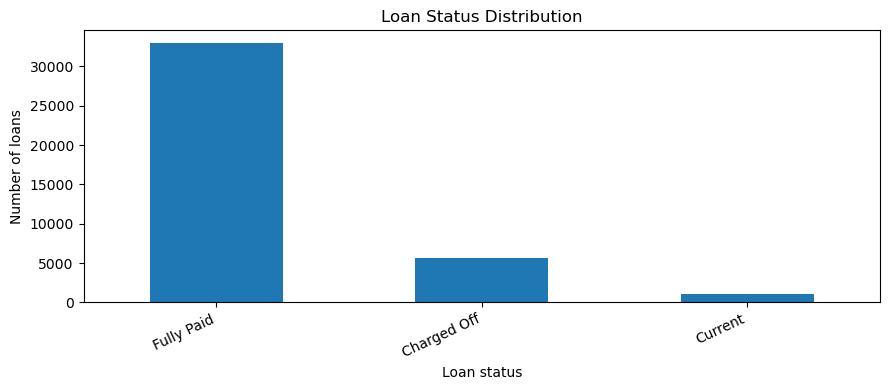

In [5]:
display(portfolio_kpis(cleaned))
if "loan_status" in cleaned.columns:
    status_counts = cleaned["loan_status"].value_counts(dropna=False)
    ax = status_counts.plot(kind="bar", figsize=(9, 4), title="Loan Status Distribution")
    ax.set_xlabel("Loan status"); ax.set_ylabel("Number of loans"); plt.xticks(rotation=25, ha="right"); plt.tight_layout()
    plt.savefig(FIGURES / "loan_status_distribution.png", dpi=180); plt.show()


## 5. Historical credit-risk analysis

The binary default flag is defined only for completed outcomes. The following analysis avoids treating active loans as repaid loans.


In [6]:
if "loan_status" in cleaned.columns:
    print("Completed-loan historical default rate:", f"{completed_loan_default_rate(cleaned):.2%}")
    for segment in ["grade", "customer_risk_tier", "purpose", "term", "home_ownership"]:
        if segment in cleaned.columns:
            display(default_rate_by_segment(cleaned, segment))


Completed-loan historical default rate: 14.59%


,grade,loan_count,charged_off_count,default_rate_pct,total_funded_amount,avg_funded_amount,avg_interest_rate_pct,total_net_credit_loss
6,G,299,101,33.78,5935725,19851.92,21.31,1.328529e+06
5,F,976,319,32.68,17037125,17456.07,19.64,3.820221e+06
4,E,2663,715,26.85,40233875,15108.48,17.63,7.038918e+06
3,D,5085,1118,21.99,60697950,11936.67,15.66,8.252254e+06
2,C,7834,1347,17.19,83003250,10595.26,13.53,8.715516e+06
1,B,11675,1425,12.21,124777250,10687.56,11.01,8.542100e+06
0,A,10045,602,5.99,84331450,8395.37,7.33,2.351549e+06


,customer_risk_tier,loan_count,charged_off_count,default_rate_pct,total_funded_amount,avg_funded_amount,avg_interest_rate_pct,total_net_credit_loss
2,Subprime,3938,1135,28.82,63206725,16050.46,18.41,1.218767e+07
0,Near-Prime,12919,2465,19.08,143701200,11123.24,14.37,1.696777e+07
1,Prime,21720,2027,9.33,209108700,9627.47,9.31,1.089365e+07


,purpose,loan_count,charged_off_count,default_rate_pct,total_funded_amount,avg_funded_amount,avg_interest_rate_pct,total_net_credit_loss
11,small_business,1754,475,27.08,22527675,12843.60,12.9,4.327060e+06
10,renewable_energy,102,19,18.63,849425,8327.70,11.44,8.413907e+04
3,educational,325,56,17.23,2174925,6692.08,11.65,2.250532e+05
9,other,3865,633,16.38,30002875,7762.71,11.72,3.110398e+06
5,house,367,59,16.08,4552275,12404.02,12.16,4.314041e+05
8,moving,576,92,15.97,3699675,6423.05,11.53,3.350703e+05
7,medical,681,106,15.57,5430475,7974.27,11.43,5.884084e+05
2,debt_consolidation,18055,2767,15.33,220422775,12208.41,12.4,2.193115e+07
12,vacation,375,53,14.13,1999650,5332.40,10.83,1.559784e+05
4,home_improvement,2875,347,12.07,31615400,10996.66,11.29,2.547645e+06


,term,loan_count,charged_off_count,default_rate_pct,total_funded_amount,avg_funded_amount,avg_interest_rate_pct,total_net_credit_loss
1,60 months,9481,2400,25.31,140503500,14819.48,14.78,2.348317e+07
0,36 months,29096,3227,11.09,275513125,9469.11,11.0,1.656591e+07


,home_ownership,loan_count,charged_off_count,default_rate_pct,total_funded_amount,avg_funded_amount,avg_interest_rate_pct,total_net_credit_loss
2,OTHER,98,18,18.37,994575,10148.72,12.04,1.349774e+05
4,RENT,18480,2839,15.36,179280025,9701.30,12.22,1.784227e+07
3,OWN,2975,443,14.89,29540325,9929.52,11.69,2.915039e+06
0,MORTGAGE,17021,2327,13.67,206184900,12113.56,11.66,1.915680e+07
1,NONE,3,0,0.00,16800,5600.00,8.7,0.000000e+00


## 6. Borrower behaviour and loan characteristics

Explore customer income, debt-to-income ratio, revolving utilization, delinquencies, inquiries, employment tenure and loan purpose where available. Interpret correlations as associations, not causal effects.


,count,mean,std,min,25%,50%,75%,90%,95%,max
loan_amnt,39717.0,11219.443815,7456.670694,500.0,5500.0,10000.0,15000.0,22000.0,25000.0,35000.0
annual_inc,39717.0,68968.926377,63793.76579,4000.0,40404.0,59000.0,82300.0,116000.0,142000.0,6000000.0
dti,39717.0,13.31513,6.678594,0.0,8.17,13.4,18.6,22.33,23.84,29.99
int_rate,39717.0,12.021177,3.724825,5.42,9.25,11.86,14.59,16.89,18.54,24.59
revol_util,39667.0,48.832152,28.332634,0.0,25.4,49.3,72.4,87.8,93.5,99.9
delinq_2yrs,39717.0,0.146512,0.491812,0.0,0.0,0.0,0.0,1.0,1.0,11.0
inq_last_6mths,39717.0,0.8692,1.070219,0.0,0.0,1.0,1.0,2.0,3.0,8.0
loan_to_income_ratio,39717.0,0.187914,0.11637,0.0008,0.1,0.1661,0.2513,0.3509,0.4167,0.83


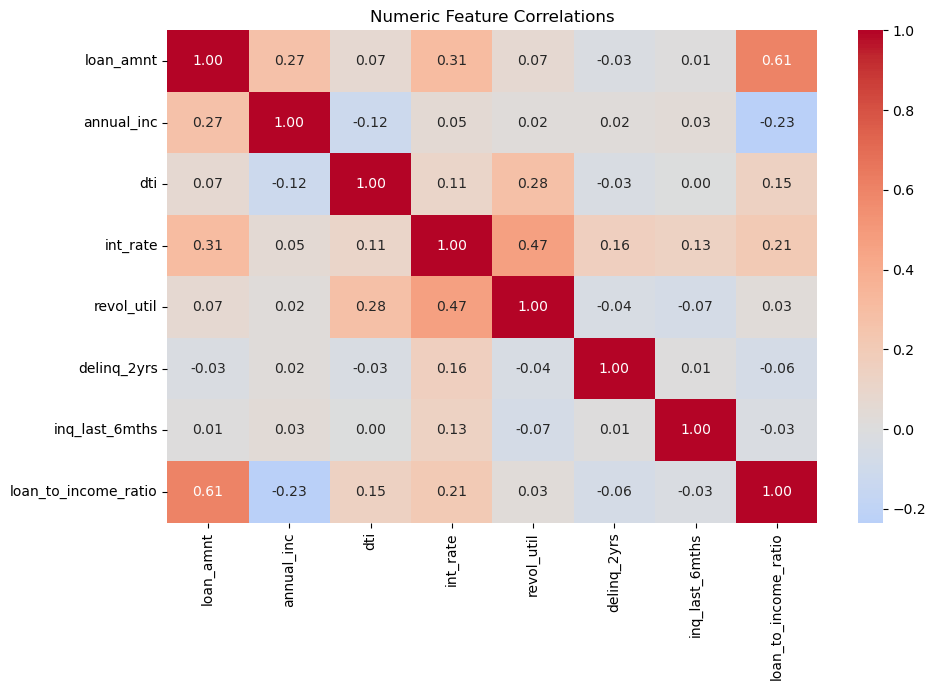

In [7]:
numeric_candidates = [c for c in ["loan_amnt", "annual_inc", "dti", "int_rate", "revol_util", "delinq_2yrs", "inq_last_6mths", "loan_to_income_ratio"] if c in cleaned.columns]
if numeric_candidates:
    display(cleaned[numeric_candidates].describe(percentiles=[.25,.5,.75,.9,.95]).T)
    corr = cleaned[numeric_candidates].corr(numeric_only=True)
    plt.figure(figsize=(10, 7)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0); plt.title("Numeric Feature Correlations"); plt.tight_layout()
    plt.savefig(FIGURES / "numeric_correlation_heatmap.png", dpi=180); plt.show()


## 7. Vintage / issue-date analysis

Vintage analysis is possible only if `issue_d` parses reliably. Compare loan origination volume by issue year; do not infer default timing from origination year without accounting for outcome maturity.


,issue_year,loan_count
0,2007,251
1,2008,1562
2,2009,4716
3,2010,11532
4,2011,21656


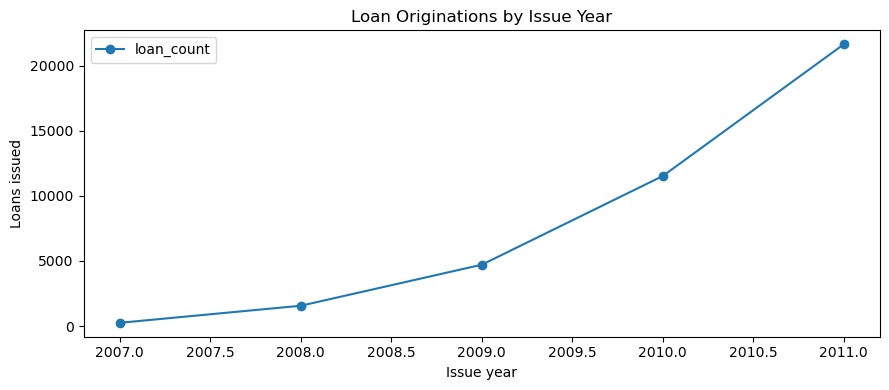

In [8]:
if "issue_year" in cleaned.columns:
    vintage = cleaned.groupby("issue_year", dropna=True).size().rename("loan_count").reset_index()
    display(vintage)
    ax = vintage.plot(x="issue_year", y="loan_count", kind="line", marker="o", figsize=(9,4), title="Loan Originations by Issue Year")
    ax.set_xlabel("Issue year"); ax.set_ylabel("Loans issued"); plt.tight_layout()
    plt.savefig(FIGURES / "loan_vintage_volume.png", dpi=180); plt.show()
else:
    print("Issue-date field unavailable; skip vintage analysis.")


## 8. Export for Power BI

Use `loans_cleaned.csv` for portfolio reporting and filter to completed outcomes for historical default-rate analysis. Validate DAX measures against Python results.


In [9]:
print("Power BI export:", PROCESSED / "loans_cleaned.csv")
print("Completed-loan export:", PROCESSED / "loans_completed_for_default_analysis.csv")
print("Figures:", list(FIGURES.glob("*.png")))


Power BI export: C:\python\Loan Portfolio & Customer Behaviour Analysis\data\processed\loans_cleaned.csv
Completed-loan export: C:\python\Loan Portfolio & Customer Behaviour Analysis\data\processed\loans_completed_for_default_analysis.csv
Figures: [WindowsPath('C:/python/Loan Portfolio & Customer Behaviour Analysis/figures/01_loan_amount_distribution.png'), WindowsPath('C:/python/Loan Portfolio & Customer Behaviour Analysis/figures/02_loan_purpose_distribution.png'), WindowsPath('C:/python/Loan Portfolio & Customer Behaviour Analysis/figures/03_interest_rate_distribution.png'), WindowsPath('C:/python/Loan Portfolio & Customer Behaviour Analysis/figures/04_customer_income_segments.png'), WindowsPath('C:/python/Loan Portfolio & Customer Behaviour Analysis/figures/05_employment_tenure.png'), WindowsPath('C:/python/Loan Portfolio & Customer Behaviour Analysis/figures/06_home_ownership.png'), WindowsPath('C:/python/Loan Portfolio & Customer Behaviour Analysis/figures/07_credit_grades_subgra